In [1]:
from pathlib import Path

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

print("Dataset exists:", dataset_path.exists())

if dataset_path.exists():
    print("\nFirst 25 files:")

    for i, file in enumerate(dataset_path.rglob("*")):
        if file.is_file():
            print(file.relative_to(dataset_path))
            if i >= 24:
                break
else:
    print("Dataset folder not found. Check the path.")

Dataset exists: True

First 25 files:
test.txt
trainval.txt
group92000\92000\92000000_temp.jpg


In [2]:
from collections import Counter

if dataset_path.exists():
    files = [p for p in dataset_path.rglob("*") if p.is_file()]

    extensions = Counter(p.suffix.lower() for p in files)

    print("File types and counts:")
    for ext, count in extensions.most_common():
        print(f"{ext or '[no extension]'}: {count}")

    print("\nPossible annotation files:")
    annotation_files = [
        p for p in files
        if p.suffix.lower() in {".txt", ".xml", ".json"}
    ]

    for file in annotation_files[:5]:
        print(f"\n--- {file.relative_to(dataset_path)} ---")
        try:
            print(file.read_text(encoding="utf-8")[:800])
        except Exception as e:
            print("Could not read:", e)

File types and counts:
.jpg: 3001
.txt: 1502

Possible annotation files:

--- test.txt ---
group20085/20085/20085291.jpg group20085/20085_not/20085291.txt
group20085/20085/20085292.jpg group20085/20085_not/20085292.txt
group20085/20085/20085293.jpg group20085/20085_not/20085293.txt
group20085/20085/20085294.jpg group20085/20085_not/20085294.txt
group20085/20085/20085295.jpg group20085/20085_not/20085295.txt
group20085/20085/20085296.jpg group20085/20085_not/20085296.txt
group20085/20085/20085297.jpg group20085/20085_not/20085297.txt
group20085/20085/20085298.jpg group20085/20085_not/20085298.txt
group20085/20085/20085299.jpg group20085/20085_not/20085299.txt
group20085/20085/20085300.jpg group20085/20085_not/20085300.txt
group20085/20085/20085301.jpg group20085/20085_not/20085301.txt
group20085/20085/20085302.jpg group20085/20085_not/20085302.txt
group20085/20085/20085303.jpg gr

--- trainval.txt ---
group20085/20085/20085000.jpg group20085/20085_not/20085000.txt
group20085/20085/20085

In [3]:
from pathlib import Path
from collections import Counter
import cv2

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

def read_split(filename):
    split_file = dataset_path / filename
    entries = []

    for line in split_file.read_text(encoding="utf-8").splitlines():
        parts = line.strip().split()
        if len(parts) == 2:
            entries.append((parts[0], parts[1]))

    return entries

trainval_entries = read_split("trainval.txt")
test_entries = read_split("test.txt")

print("Train/validation pairs:", len(trainval_entries))
print("Test pairs:", len(test_entries))

# Check paths and annotation contents
class_counts = Counter()
missing_images = []
missing_labels = []
empty_labels = []
invalid_lines = []
image_dimensions = Counter()

all_entries = [
    ("trainval", entry) for entry in trainval_entries
] + [
    ("test", entry) for entry in test_entries
]

for split_name, (image_rel, label_rel) in all_entries:
    image_path = dataset_path / image_rel
    label_path = dataset_path / label_rel

    if not image_path.exists():
        missing_images.append(str(image_path))
        continue

    if not label_path.exists():
        missing_labels.append(str(label_path))
        continue

    image = cv2.imread(str(image_path))
    if image is not None:
        height, width = image.shape[:2]
        image_dimensions[(width, height)] += 1

    lines = label_path.read_text(encoding="utf-8").splitlines()

    if not any(line.strip() for line in lines):
        empty_labels.append(str(label_path))

    for line_number, line in enumerate(lines, start=1):
        if not line.strip():
            continue

        values = line.split()

        if len(values) != 5:
            invalid_lines.append(
                (str(label_path), line_number, line)
            )
            continue

        try:
            x1, y1, x2, y2 = map(float, values[:4])
            class_id = int(values[4])

            if class_id not in range(1, 7):
                invalid_lines.append(
                    (str(label_path), line_number, line)
                )
                continue

            class_counts[class_id] += 1

            if not (x1 < x2 and y1 < y2):
                invalid_lines.append(
                    (str(label_path), line_number, line)
                )

        except ValueError:
            invalid_lines.append(
                (str(label_path), line_number, line)
            )

print("\nImage dimensions:", image_dimensions)
print("Missing images:", len(missing_images))
print("Missing annotation files:", len(missing_labels))
print("Empty annotation files:", len(empty_labels))
print("Invalid annotation lines:", len(invalid_lines))

print("\nBounding boxes per original class ID:")
for class_id in sorted(class_counts):
    print(f"Class {class_id}: {class_counts[class_id]}")

if missing_images:
    print("\nFirst missing image:", missing_images[0])

if missing_labels:
    print("First missing label:", missing_labels[0])

if invalid_lines:
    print("First invalid annotation:", invalid_lines[0])

Train/validation pairs: 1000
Test pairs: 500

Image dimensions: Counter()
Missing images: 1500
Missing annotation files: 0
Empty annotation files: 0
Invalid annotation lines: 0

Bounding boxes per original class ID:

First missing image: D:\DeepPCB-master\DeepPCB-master\PCBData\group20085\20085\20085000.jpg


In [4]:
from pathlib import Path

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

print("Dataset root:", dataset_path)
print("\nTop-level entries:")

for item in list(dataset_path.iterdir())[:20]:
    print("DIR " if item.is_dir() else "FILE", item.name)

print("\nSearching for the missing image by filename...")

target = "20085000.jpg"

matches = list(dataset_path.rglob(target))

if matches:
    for match in matches[:10]:
        print("FOUND:", match)
else:
    print("Exact filename not found.")

print("\nSearching for actual PCB images...")

image_files = list(dataset_path.rglob("*.jpg"))

print("Total JPG files found:", len(image_files))

for image in image_files[:15]:
    print(image.relative_to(dataset_path))

Dataset root: D:\DeepPCB-master\DeepPCB-master\PCBData

Top-level entries:
DIR  group00041
DIR  group12000
DIR  group12100
DIR  group12300
DIR  group13000
DIR  group20085
DIR  group44000
DIR  group50600
DIR  group77000
DIR  group90100
DIR  group92000
FILE test.txt
FILE trainval.txt

Searching for the missing image by filename...
Exact filename not found.

Searching for actual PCB images...
Total JPG files found: 3001
group92000\92000\92000000_temp.jpg
group92000\92000\92000000_test.jpg
group92000\92000\92000001_temp.jpg
group92000\92000\92000001_test.jpg
group92000\92000\92000002_temp.jpg
group92000\92000\92000002_test.jpg
group92000\92000\92000003_temp.jpg
group92000\92000\92000003_test.jpg
group92000\92000\92000004_temp.jpg
group92000\92000\92000004_test.jpg
group92000\92000\92000005_temp.jpg
group92000\92000\92000005_test.jpg
group92000\92000\92000006_temp.jpg
group92000\92000\92000006_test.jpg
group92000\92000\92000007_temp.jpg


In [5]:
from pathlib import Path

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

# Inspect one group
group = dataset_path / "group92000"

print("Files in group92000:")
for file in sorted(group.rglob("*"))[:30]:
    if file.is_file():
        print(file.relative_to(dataset_path))

# Check corresponding annotation folder
annotation_folder = group / "92000_not"

print("\nAnnotation examples:")
if annotation_folder.exists():
    for file in sorted(annotation_folder.glob("*.txt"))[:5]:
        print(f"\n{file.name}")
        print(file.read_text(encoding="utf-8")[:300])
else:
    print("Annotation folder not found:", annotation_folder)

Files in group92000:
group92000\92000\92000000_temp.jpg
group92000\92000\92000000_test.jpg
group92000\92000\92000001_temp.jpg
group92000\92000\92000001_test.jpg
group92000\92000\92000002_temp.jpg
group92000\92000\92000002_test.jpg
group92000\92000\92000003_temp.jpg
group92000\92000\92000003_test.jpg
group92000\92000\92000004_temp.jpg
group92000\92000\92000004_test.jpg
group92000\92000\92000005_temp.jpg
group92000\92000\92000005_test.jpg
group92000\92000\92000006_temp.jpg
group92000\92000\92000006_test.jpg
group92000\92000\92000007_temp.jpg
group92000\92000\92000007_test.jpg
group92000\92000\92000008_temp.jpg
group92000\92000\92000008_test.jpg
group92000\92000\92000009_temp.jpg
group92000\92000\92000009_test.jpg
group92000\92000\92000010_temp.jpg
group92000\92000\92000010_test.jpg
group92000\92000\92000011_temp.jpg
group92000\92000\92000011_test.jpg
group92000\92000\92000012_temp.jpg
group92000\92000\92000012_test.jpg
group92000\92000\92000013_temp.jpg
group92000\92000\92000013_test.jpg

In [6]:
from pathlib import Path

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

for line in (dataset_path / "trainval.txt").read_text(
    encoding="utf-8"
).splitlines()[:5]:
    image_rel, label_rel = line.split()

    image_stem = Path(image_rel).stem
    label_stem = Path(label_rel).stem

    print(f"\nSplit image: {image_stem}")
    print("Listed label:", label_stem)

    image_parent = dataset_path / Path(image_rel).parent
    label_parent = dataset_path / Path(label_rel).parent

    if image_parent.exists():
        candidates = list(image_parent.glob(f"{image_stem}*"))
        print("Matching image files:", [p.name for p in candidates])
    else:
        print("Listed image directory does not exist:", image_parent)

    if label_parent.exists():
        candidates = list(label_parent.glob(f"{label_stem}*"))
        print("Matching label files:", [p.name for p in candidates])
    else:
        print("Listed label directory does not exist:", label_parent)


Split image: 20085000
Listed label: 20085000
Matching image files: ['20085000_temp.jpg', '20085000_test.jpg']
Matching label files: ['20085000.txt']

Split image: 20085001
Listed label: 20085001
Matching image files: ['20085001_temp.jpg', '20085001_test.jpg']
Matching label files: ['20085001.txt']

Split image: 20085002
Listed label: 20085002
Matching image files: ['20085002_temp.jpg', '20085002_test.jpg']
Matching label files: ['20085002.txt']

Split image: 20085003
Listed label: 20085003
Matching image files: ['20085003_temp.jpg', '20085003_test.jpg']
Matching label files: ['20085003.txt']

Split image: 20085004
Listed label: 20085004
Matching image files: ['20085004_temp.jpg', '20085004_test.jpg']
Matching label files: ['20085004.txt']


Temp image loaded: True
Test image loaded: True
Temp dimensions: (640, 640)
Test dimensions: (640, 640)


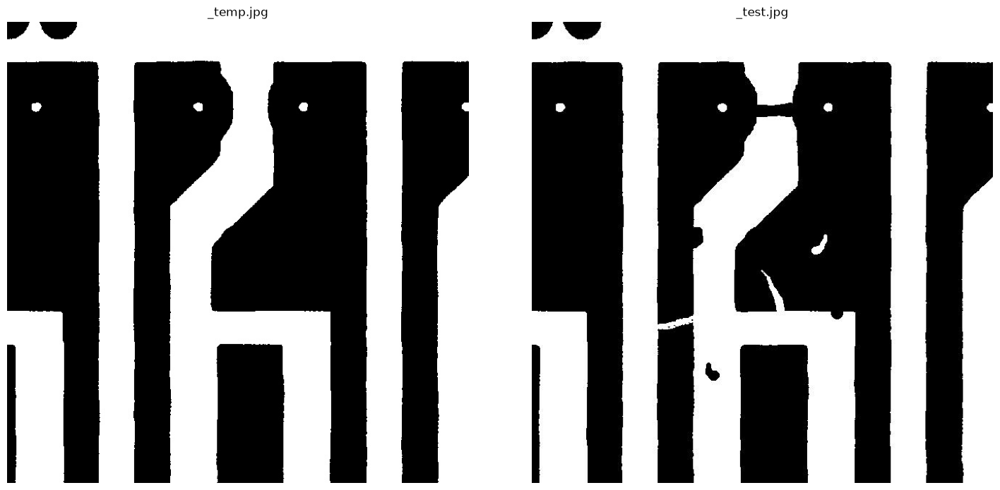


Annotations:
162 397 243 436 1
296 102 377 141 2
308 334 360 415 3
207 275 247 323 4
405 386 441 422 4
378 285 419 332 6
231 463 270 507 5



In [7]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

dataset_path = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

sample_id = "92000000"
image_dir = dataset_path / "group92000" / "92000"
label_path = dataset_path / "group92000" / "92000_not" / f"{sample_id}.txt"

temp_path = image_dir / f"{sample_id}_temp.jpg"
test_path = image_dir / f"{sample_id}_test.jpg"

temp = cv2.imread(str(temp_path))
test = cv2.imread(str(test_path))

print("Temp image loaded:", temp is not None)
print("Test image loaded:", test is not None)
print("Temp dimensions:", temp.shape[:2] if temp is not None else None)
print("Test dimensions:", test.shape[:2] if test is not None else None)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, img, title in [
    (axes[0], temp, "_temp.jpg"),
    (axes[1], test, "_test.jpg")
]:
    if img is not None:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\nAnnotations:")
print(label_path.read_text(encoding="utf-8"))

In [8]:
from pathlib import Path
import random
import shutil
import cv2
import yaml

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

source = Path(r"D:\DeepPCB-master\DeepPCB-master\PCBData")

output = Path(
    r"D:\PCB Defect Detection\datasets\deeppcb_yolo"
)

random_seed = 42
random.seed(random_seed)

class_names = [
    "open",
    "short",
    "mousebite",
    "spur",
    "copper",
    "pin-hole",
]

# --------------------------------------------------
# 2. Read official split lists
# --------------------------------------------------

def read_split(filename):
    entries = []

    for line in (source / filename).read_text(
        encoding="utf-8"
    ).splitlines():
        parts = line.strip().split()

        if len(parts) == 2:
            entries.append((parts[0], parts[1]))

    return entries


trainval_entries = read_split("trainval.txt")
test_entries = read_split("test.txt")

random.shuffle(trainval_entries)

val_entries = trainval_entries[:100]
train_entries = trainval_entries[100:]

splits = {
    "train": train_entries,
    "val": val_entries,
    "test": test_entries,
}

print("Planned split sizes:")
for name, entries in splits.items():
    print(f"{name}: {len(entries)} images")

# --------------------------------------------------
# 3. Convert annotations and copy images
# --------------------------------------------------

def convert_annotation(label_path, image_width, image_height):
    converted = []

    for line_number, line in enumerate(
        label_path.read_text(encoding="utf-8").splitlines(),
        start=1,
    ):
        if not line.strip():
            continue

        parts = line.split()

        if len(parts) != 5:
            raise ValueError(
                f"Invalid annotation at {label_path}, line {line_number}"
            )

        x1, y1, x2, y2 = map(float, parts[:4])
        original_class = int(parts[4])

        if original_class not in range(1, 7):
            raise ValueError(
                f"Unexpected class ID {original_class}: {label_path}"
            )

        if not (
            0 <= x1 < x2 <= image_width
            and 0 <= y1 < y2 <= image_height
        ):
            raise ValueError(
                f"Invalid bounding box in {label_path}: {line}"
            )

        # DeepPCB class IDs 1-6 -> YOLO class IDs 0-5
        class_id = original_class - 1

        # Convert pixel xyxy -> normalized xywh
        x_center = ((x1 + x2) / 2) / image_width
        y_center = ((y1 + y2) / 2) / image_height
        box_width = (x2 - x1) / image_width
        box_height = (y2 - y1) / image_height

        converted.append(
            f"{class_id} {x_center:.6f} {y_center:.6f} "
            f"{box_width:.6f} {box_height:.6f}"
        )

    return converted


# Validate source pairs before writing anything
validated = {}

for split_name, entries in splits.items():
    validated[split_name] = []

    for image_rel, label_rel in entries:
        listed_image = Path(image_rel)
        listed_label = Path(label_rel)

        image_path = source / listed_image.parent / (
            listed_image.stem + "_test.jpg"
        )
        label_path = source / label_rel

        if not image_path.is_file():
            raise FileNotFoundError(
                f"Missing tested image: {image_path}"
            )

        if not label_path.is_file():
            raise FileNotFoundError(
                f"Missing annotation: {label_path}"
            )

        image = cv2.imread(str(image_path))

        if image is None:
            raise ValueError(f"Could not read image: {image_path}")

        height, width = image.shape[:2]

        labels = convert_annotation(
            label_path, width, height
        )

        validated[split_name].append(
            (image_path, listed_image.stem, labels)
        )

print("\nAll source image/annotation pairs validated.")

# --------------------------------------------------
# 4. Create output folders
# --------------------------------------------------

for split_name in splits:
    (output / "images" / split_name).mkdir(
        parents=True, exist_ok=True
    )
    (output / "labels" / split_name).mkdir(
        parents=True, exist_ok=True
    )

# --------------------------------------------------
# 5. Copy images and write YOLO labels
# --------------------------------------------------

for split_name, records in validated.items():
    for image_path, stem, labels in records:
        destination_image = (
            output / "images" / split_name / f"{stem}.jpg"
        )
        destination_label = (
            output / "labels" / split_name / f"{stem}.txt"
        )

        shutil.copy2(image_path, destination_image)

        destination_label.write_text(
            "\n".join(labels) + ("\n" if labels else ""),
            encoding="utf-8",
        )

# --------------------------------------------------
# 6. Write Ultralytics dataset configuration
# --------------------------------------------------

config = {
    "path": str(output),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        i: name for i, name in enumerate(class_names)
    },
}

yaml_path = output / "deeppcb.yaml"

with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True,
    )

print("\nDataset preparation complete.")
print("Dataset location:", output)
print("YOLO config:", yaml_path)

for split_name, records in validated.items():
    print(f"{split_name}: {len(records)} images copied")

Planned split sizes:
train: 900 images
val: 100 images
test: 500 images

All source image/annotation pairs validated.

Dataset preparation complete.
Dataset location: D:\PCB Defect Detection\datasets\deeppcb_yolo
YOLO config: D:\PCB Defect Detection\datasets\deeppcb_yolo\deeppcb.yaml
train: 900 images copied
val: 100 images copied
test: 500 images copied


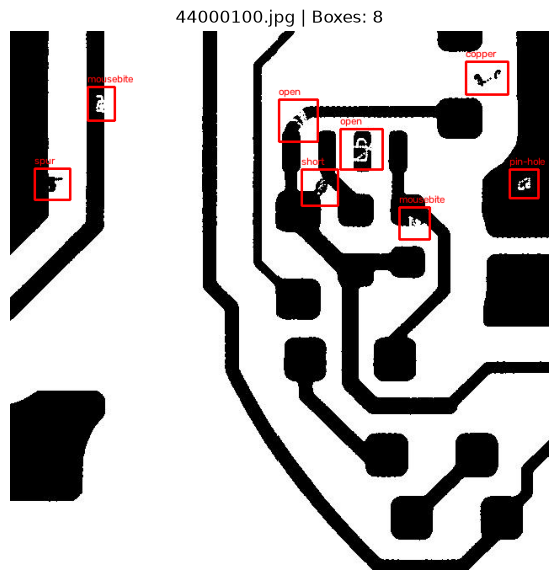

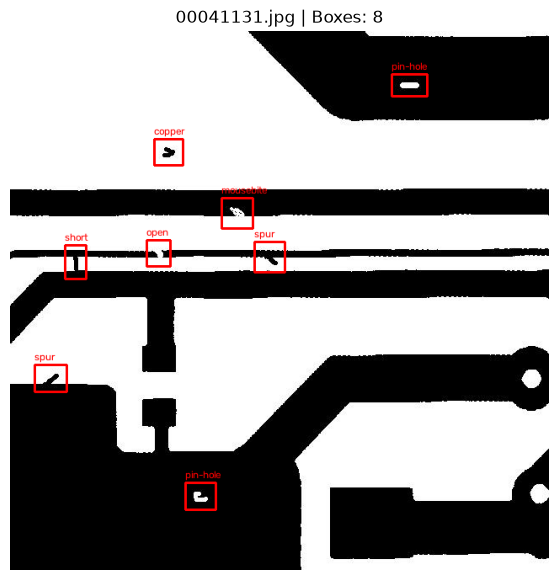

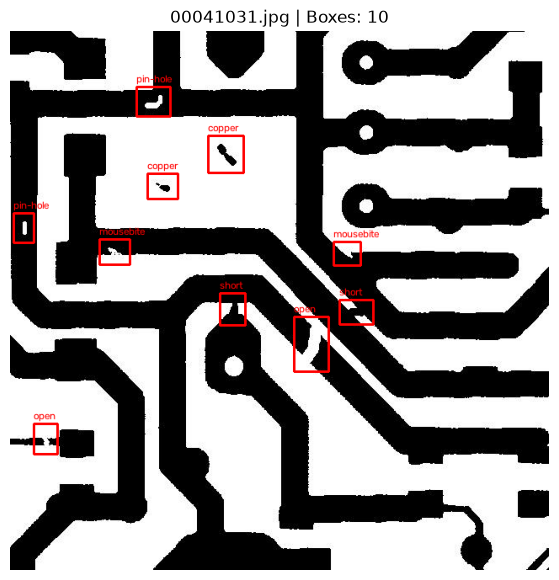

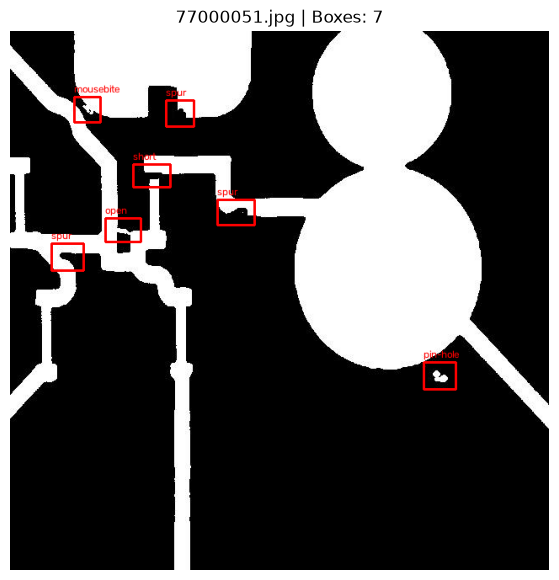

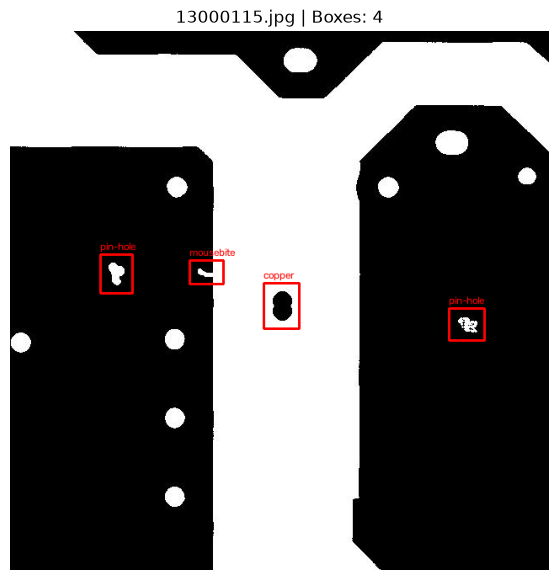

In [9]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

dataset_dir = Path(
    r"D:\PCB Defect Detection\datasets\deeppcb_yolo"
)

class_names = [
    "open", "short", "mousebite",
    "spur", "copper", "pin-hole"
]

image_dir = dataset_dir / "images" / "train"
label_dir = dataset_dir / "labels" / "train"

image_files = list(image_dir.glob("*.jpg"))

random.seed(42)
samples = random.sample(image_files, min(5, len(image_files)))

for image_path in samples:
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]
    label_path = label_dir / f"{image_path.stem}.txt"

    box_count = 0

    if label_path.exists():
        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():
            if not line.strip():
                continue

            class_id, xc, yc, bw, bh = map(
                float, line.split()
            )

            class_id = int(class_id)

            x1 = int((xc - bw / 2) * width)
            y1 = int((yc - bh / 2) * height)
            x2 = int((xc + bw / 2) * width)
            y2 = int((yc + bh / 2) * height)

            cv2.rectangle(
                image, (x1, y1), (x2, y2),
                (255, 0, 0), 2
            )

            label = class_names[class_id]

            cv2.putText(
                image, label,
                (x1, max(y1 - 5, 12)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.4, (255, 0, 0), 1,
                cv2.LINE_AA
            )

            box_count += 1

    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    plt.title(f"{image_path.name} | Boxes: {box_count}")
    plt.axis("off")
    plt.show()

In [10]:
from pathlib import Path
from ultralytics import YOLO
import torch

data_yaml = Path(
    r"D:\PCB Defect Detection\datasets\deeppcb_yolo\deeppcb.yaml"
)

assert data_yaml.exists(), f"Dataset YAML not found: {data_yaml}"

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(data_yaml),
    epochs=50,
    imgsz=640,
    batch=4,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=0,
    project=r"D:\PCB Defect Detection\results",
    name="deeppcb_yolo_baseline",
    exist_ok=True,
    patience=10,
    plots=True,
    seed=42
)

print("Training finished.")
print("Best model should be saved at:")
print(
    r"D:\PCB Defect Detection\results"
    r"\deeppcb_yolo_baseline\weights\best.pt"
)

CUDA available: True
GPU: NVIDIA GeForce RTX 2050
New https://pypi.org/project/ultralytics/8.4.182 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\PCB Defect Detection\datasets\deeppcb_yolo\deeppcb.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=

In [11]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    r"D:\PCB Defect Detection\results\deeppcb_yolo_baseline\weights\best.pt"
)

data_yaml = Path(
    r"D:\PCB Defect Detection\datasets\deeppcb_yolo\deeppcb.yaml"
)

model = YOLO(str(model_path))

metrics = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=0,
    plots=True,
    project=r"D:\PCB Defect Detection\results",
    name="deeppcb_test_evaluation",
    exist_ok=True
)

print("Test Precision:", round(metrics.box.mp, 4))
print("Test Recall:", round(metrics.box.mr, 4))
print("Test mAP50:", round(metrics.box.map50, 4))
print("Test mAP50-95:", round(metrics.box.map, 4))

Ultralytics 8.4.163  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 1.50.6 MB/s, size: 28.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\PCB Defect Detection\datasets\deeppcb_yolo\labels\test... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 183.0it/s 2.7s0.1s
val: New cache created: D:\PCB Defect Detection\datasets\deeppcb_yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 9.9it/s 12.6s<0.1s
                   all        500       3140      0.926      0.916      0.957      0.682
                  open        482        659      0.959       0.93      0.974      0.632
                 short        368


Image: college_pcb_phone_light_2.jpg
Detections: 300
Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_deeppcb_full.jpg
  copper: 0.876
  copper: 0.824
  copper: 0.756
  copper: 0.669
  copper: 0.649
  copper: 0.612
  copper: 0.590
  copper: 0.574
  copper: 0.566
  copper: 0.563
  copper: 0.557
  copper: 0.555
  copper: 0.547
  copper: 0.538
  copper: 0.538
  copper: 0.532
  copper: 0.515
  copper: 0.511
  copper: 0.510
  copper: 0.507
  copper: 0.505
  copper: 0.505
  copper: 0.494
  copper: 0.493
  copper: 0.486
  copper: 0.480
  copper: 0.473
  copper: 0.467
  copper: 0.463
  copper: 0.462
  copper: 0.462
  copper: 0.458
  copper: 0.457
  copper: 0.455
  copper: 0.454
  copper: 0.450
  copper: 0.449
  copper: 0.448
  copper: 0.447
  copper: 0.445
  copper: 0.445
  copper: 0.442
  copper: 0.439
  copper: 0.439
  copper: 0.439
  copper: 0.438
  copper: 0.435
  copper: 0.434
  copper: 0.432
  copper: 0.430
  copper: 0.430
  copper: 0.427
  copper: 0.426
  copper

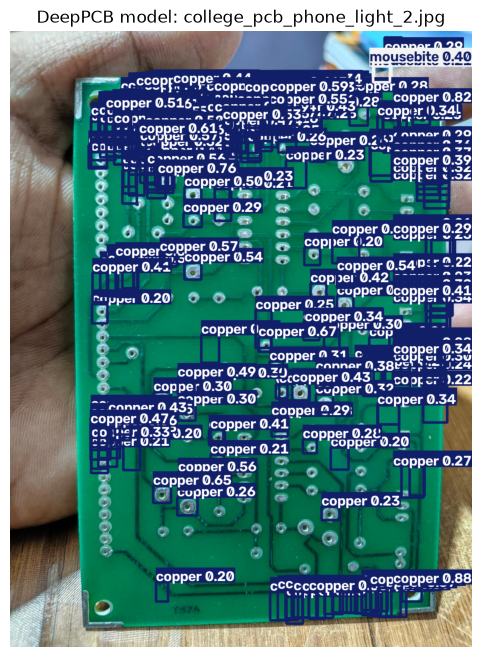


Image: college_pcb_phone_2.jpg
Detections: 46
Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_deeppcb_full.jpg
  spur: 0.545
  spur: 0.458
  short: 0.422
  spur: 0.367
  short: 0.360
  spur: 0.345
  short: 0.282
  short: 0.269
  spur: 0.245
  spur: 0.238
  short: 0.218
  spur: 0.217
  short: 0.213
  spur: 0.213
  mousebite: 0.206
  spur: 0.204
  spur: 0.202
  spur: 0.201
  spur: 0.200
  mousebite: 0.185
  short: 0.184
  short: 0.177
  short: 0.175
  spur: 0.173
  short: 0.167
  spur: 0.166
  short: 0.159
  short: 0.156
  short: 0.150
  mousebite: 0.150
  short: 0.148
  spur: 0.142
  spur: 0.135
  spur: 0.134
  short: 0.132
  mousebite: 0.132
  spur: 0.126
  mousebite: 0.123
  mousebite: 0.121
  mousebite: 0.115
  short: 0.113
  spur: 0.109
  short: 0.107
  spur: 0.107
  short: 0.106
  short: 0.104


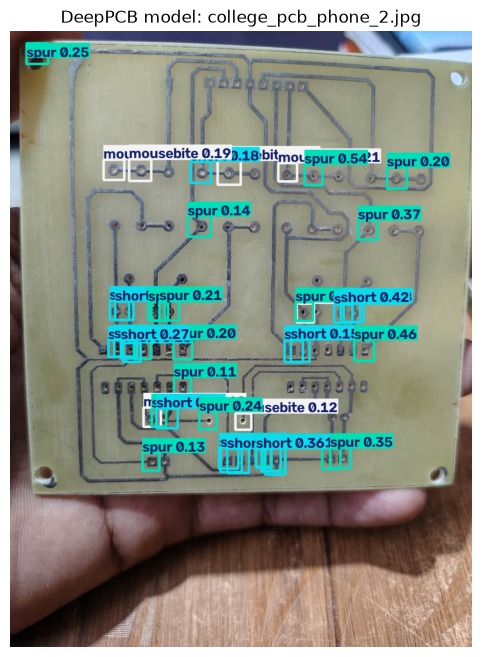

In [12]:
from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Trained DeepPCB model
model_path = Path(
    r"D:\PCB Defect Detection\results"
    r"\deeppcb_yolo_baseline\weights\best.pt"
)

# Original RGB PCB photographs
image_paths = [
    Path(
        r"D:\PCB Defect Detection\pcb_test_images"
        r"\college_pcb_phone_light_2.jpg"
    ),
    Path(
        r"D:\PCB Defect Detection\pcb_test_images"
        r"\college_pcb_phone_2.jpg"
    ),
]

model = YOLO(str(model_path))

for image_path in image_paths:
    if not image_path.exists():
        print(f"Image not found: {image_path}")
        continue

    results = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.10,
        device=0,
        verbose=False
    )

    result = results[0]
    annotated = result.plot()

    output_path = image_path.with_name(
        image_path.stem + "_deeppcb_full.jpg"
    )

    cv2.imwrite(str(output_path), annotated)

    print(f"\nImage: {image_path.name}")
    print("Detections:", len(result.boxes))
    print("Saved:", output_path)

    if len(result.boxes):
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            print(
                f"  {model.names[class_id]}: "
                f"{confidence:.3f}"
            )

    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title(f"DeepPCB model: {image_path.name}")
    plt.axis("off")
    plt.show()


RGB
Detections: 300
Class counts: {'copper': 298, 'mousebite': 2}
Mean confidence: 0.337
Saved: D:\PCB Defect Detection\results\deeppcb_preprocessing_experiment\rgb_annotated.jpg


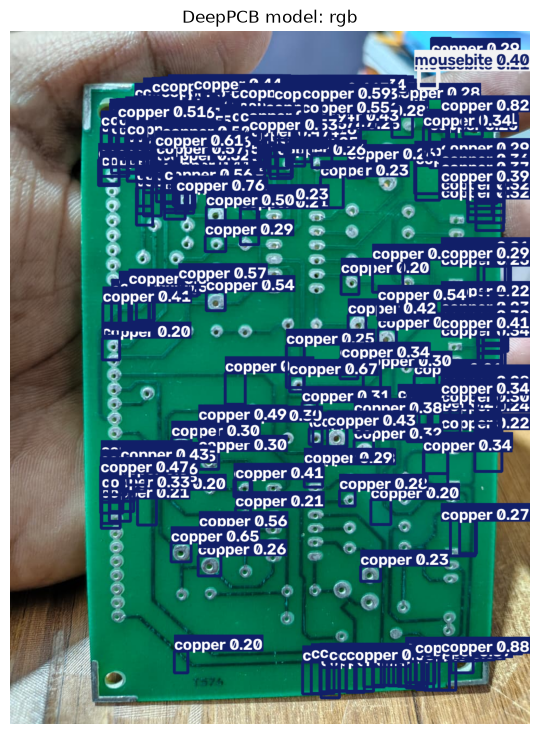


GRAYSCALE
Detections: 147
Class counts: {'pin-hole': 144, 'mousebite': 2, 'short': 1}
Mean confidence: 0.592
Saved: D:\PCB Defect Detection\results\deeppcb_preprocessing_experiment\grayscale_annotated.jpg


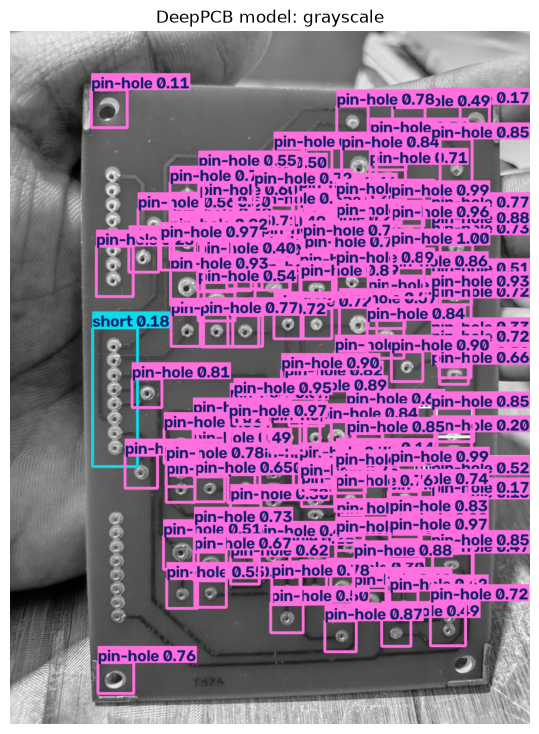


BINARY_OTSU
Detections: 194
Class counts: {'pin-hole': 172, 'spur': 10, 'short': 3, 'open': 4, 'copper': 1, 'mousebite': 4}
Mean confidence: 0.562
Saved: D:\PCB Defect Detection\results\deeppcb_preprocessing_experiment\binary_otsu_annotated.jpg


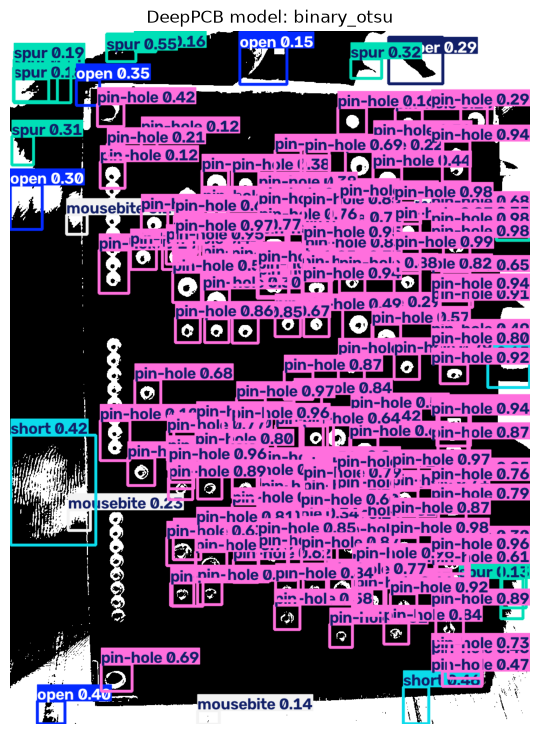


COMPARISON SUMMARY
rgb | detections: 300 | classes: {'copper': 298, 'mousebite': 2} | mean confidence: 0.337
grayscale | detections: 147 | classes: {'pin-hole': 144, 'mousebite': 2, 'short': 1} | mean confidence: 0.592
binary_otsu | detections: 194 | classes: {'pin-hole': 172, 'spur': 10, 'short': 3, 'open': 4, 'copper': 1, 'mousebite': 4} | mean confidence: 0.562


In [13]:

from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from collections import Counter

# Paths
model_path = Path(
    r"D:\PCB Defect Detection\results"
    r"\deeppcb_yolo_baseline\weights\best.pt"
)

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images"
    r"\college_pcb_phone_light_2.jpg"
)

output_dir = Path(
    r"D:\PCB Defect Detection\results"
    r"\deeppcb_preprocessing_experiment"
)
output_dir.mkdir(parents=True, exist_ok=True)

assert model_path.exists(), f"Model not found: {model_path}"
assert image_path.exists(), f"Image not found: {image_path}"

model = YOLO(str(model_path))

# Load original image in BGR format
bgr = cv2.imread(str(image_path))
if bgr is None:
    raise ValueError("Could not load the PCB image.")

# Create three versions
rgb_input = bgr.copy()

gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_3ch = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

_, binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
binary_3ch = cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)

versions = {
    "rgb": rgb_input,
    "grayscale": gray_3ch,
    "binary_otsu": binary_3ch,
}

summary = []

for name, image in versions.items():
    # Save the transformed input for visual inspection
    input_path = output_dir / f"{name}_input.jpg"
    cv2.imwrite(str(input_path), image)

    # Use identical inference settings for each version
    result = model.predict(
        source=image,
        imgsz=640,
        conf=0.10,
        iou=0.70,
        device=0,
        verbose=False
    )[0]

    annotated = result.plot()
    output_path = output_dir / f"{name}_annotated.jpg"
    cv2.imwrite(str(output_path), annotated)

    class_counts = Counter()
    confidences = []

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        class_counts[model.names[class_id]] += 1
        confidences.append(confidence)

    summary.append({
        "version": name,
        "detections": len(result.boxes),
        "classes": dict(class_counts),
        "mean_confidence": (
            round(sum(confidences) / len(confidences), 3)
            if confidences else 0
        ),
        "output": str(output_path),
    })

    print(f"\n{name.upper()}")
    print("Detections:", len(result.boxes))
    print("Class counts:", dict(class_counts))
    print("Mean confidence:", summary[-1]["mean_confidence"])
    print("Saved:", output_path)

    # Display the annotated image
    plt.figure(figsize=(9, 9))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title(f"DeepPCB model: {name}")
    plt.axis("off")
    plt.show()

print("\nCOMPARISON SUMMARY")
for item in summary:
    print(
        item["version"],
        "| detections:", item["detections"],
        "| classes:", item["classes"],
        "| mean confidence:", item["mean_confidence"]
    )


Original image dimensions: (1280, 960, 3)
Largest contour area: 884146
Percentage of image: 72.0%


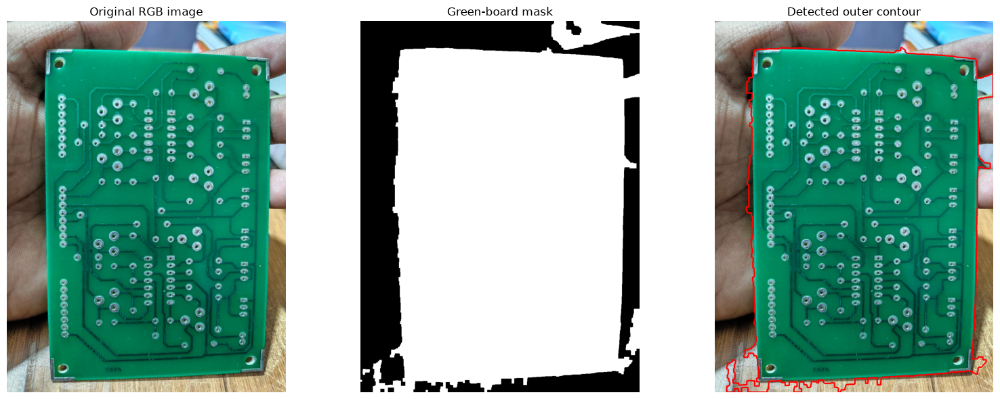

In [14]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

output_dir = Path(
    r"D:\PCB Defect Detection\results\pcb_cropping"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Load original RGB photograph
image_bgr = cv2.imread(str(image_path))

if image_bgr is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Original image dimensions:", image_rgb.shape)

# Convert to HSV for green-board segmentation
hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

lower_green = np.array([25, 30, 20])
upper_green = np.array([100, 255, 255])

mask = cv2.inRange(hsv, lower_green, upper_green)

# Clean small gaps and isolated noise
kernel = np.ones((7, 7), np.uint8)
mask = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel, iterations=2
)
mask = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel, iterations=1
)

# Find the external board contour
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError(
        "No green PCB contour detected. We need to adjust the HSV thresholds."
    )

board_contour = max(contours, key=cv2.contourArea)
contour_area = cv2.contourArea(board_contour)
image_area = image_rgb.shape[0] * image_rgb.shape[1]

print(f"Largest contour area: {contour_area:.0f}")
print(f"Percentage of image: {100 * contour_area / image_area:.1f}%")

# Reject a tiny contour that is unlikely to be the board
if contour_area < 0.05 * image_area:
    raise RuntimeError(
        "Detected green region is too small to be the PCB."
    )

# Display segmentation before perspective correction
contour_preview = image_rgb.copy()
cv2.drawContours(
    contour_preview,
    [board_contour],
    -1,
    (255, 0, 0),
    4
)

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(image_rgb)
axes[0].set_title("Original RGB image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Green-board mask")

axes[2].imshow(contour_preview)
axes[2].set_title("Detected outer contour")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Image dimensions: (960, 1280)
Largest contour area: 913548
Approximation vertices: 6
Approximation points:
[[ 959   28]
 [ 137  100]
 [  42 1279]
 [ 904 1219]
 [ 959  181]
 [ 719   96]]


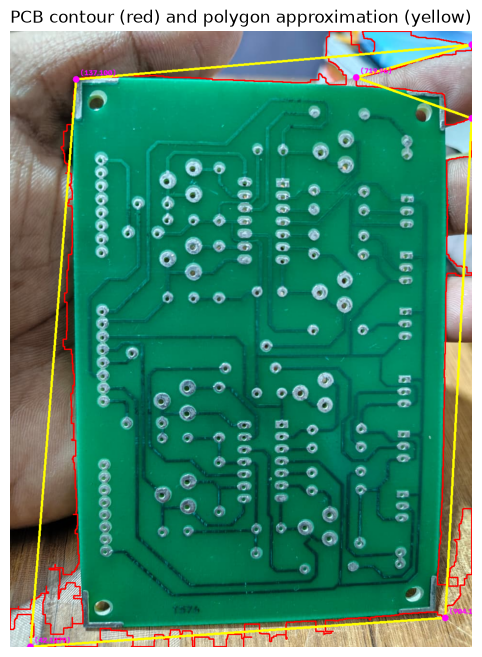

In [15]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
h, w = image.shape[:2]

# Detect the green PCB substrate in HSV color space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
lower_green = np.array([25, 30, 20])
upper_green = np.array([100, 255, 255])

green_mask = cv2.inRange(hsv, lower_green, upper_green)

# Clean small gaps and noise
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
green_mask = cv2.morphologyEx(
    green_mask, cv2.MORPH_CLOSE, kernel, iterations=2
)

# Find external contours
contours, _ = cv2.findContours(
    green_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError("No green PCB contour detected.")

# Start with the largest contour
largest = max(contours, key=cv2.contourArea)

# Approximate its outline
perimeter = cv2.arcLength(largest, True)
approx = cv2.approxPolyDP(largest, 0.02 * perimeter, True)

# Show the original contour and its polygon approximation
preview = image_rgb.copy()

cv2.drawContours(preview, [largest], -1, (255, 0, 0), 2)
cv2.drawContours(preview, [approx], -1, (255, 255, 0), 3)

for point in approx:
    x, y = point[0]
    cv2.circle(preview, (x, y), 7, (255, 0, 255), -1)
    cv2.putText(
        preview, f"({x},{y})", (x + 8, y - 8),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 255), 2
    )

print("Image dimensions:", (w, h))
print("Largest contour area:", round(cv2.contourArea(largest)))
print("Approximation vertices:", len(approx))
print("Approximation points:")
print(approx.reshape(-1, 2))

plt.figure(figsize=(10, 8))
plt.imshow(preview)
plt.title("PCB contour (red) and polygon approximation (yellow)")
plt.axis("off")
plt.show()


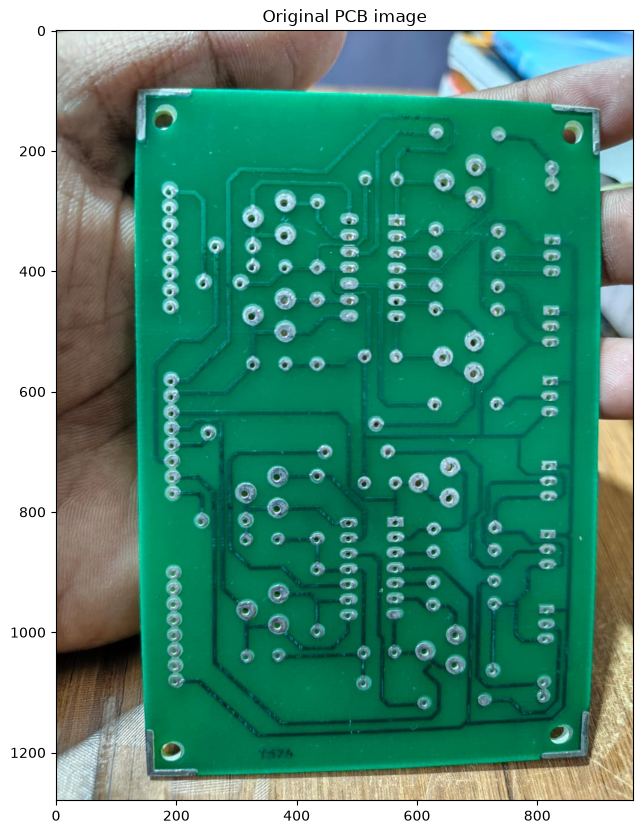

In [1]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 10))
plt.imshow(image_rgb)
plt.title("Original PCB image")
plt.axis("on")
plt.show()

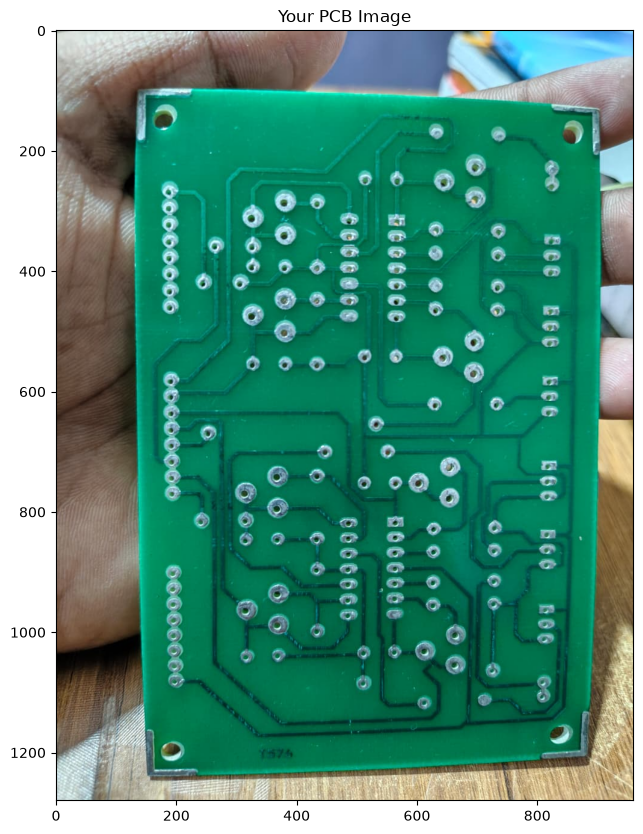

In [2]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

image = cv2.imread(str(image_path))

if image is None:
    print("Image not found. Check the file path.")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 10))
    plt.imshow(image_rgb)
    plt.title("Your PCB Image")
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_19952\1612291188.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  points = plt.ginput(4, timeout=0)


KeyboardInterrupt: 

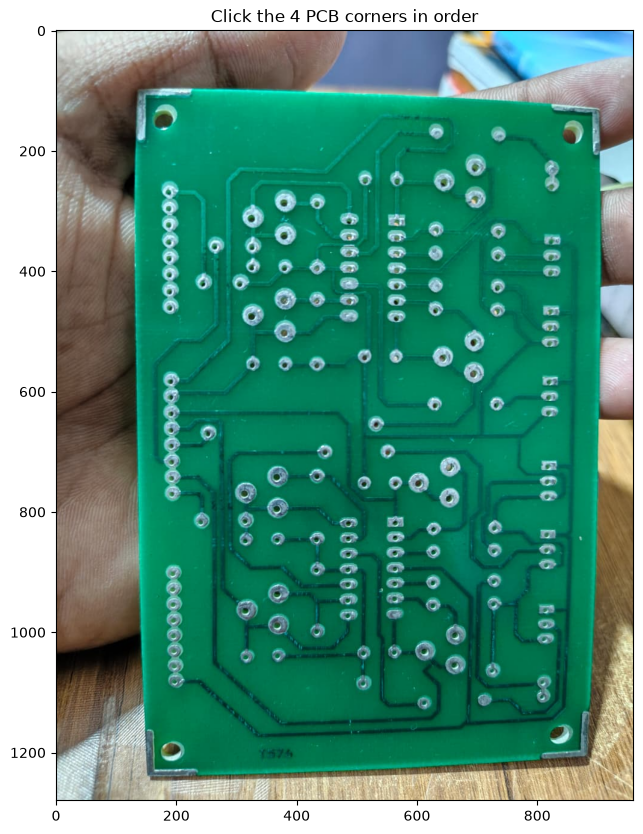

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 10))
plt.imshow(image_rgb)
plt.title("Click the 4 PCB corners in order")

points = plt.ginput(4, timeout=0)

plt.close()

print("Selected points:", points)

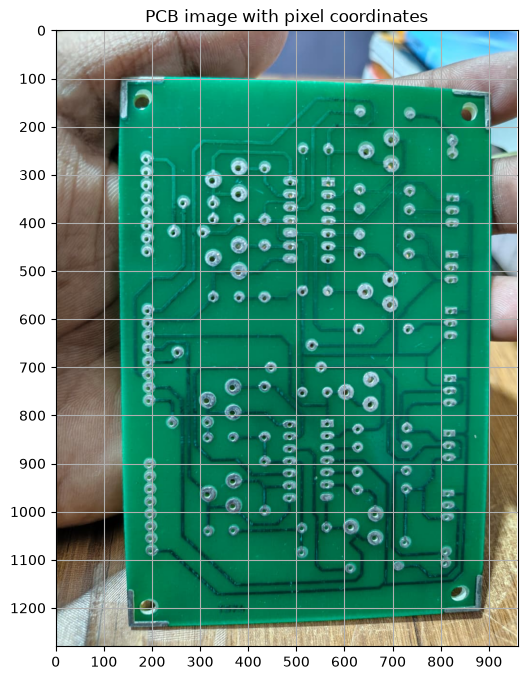

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.xlim(0, image_rgb.shape[1])
plt.ylim(image_rgb.shape[0], 0)
plt.xticks(range(0, image_rgb.shape[1] + 1, 100))
plt.yticks(range(0, image_rgb.shape[0] + 1, 100))
plt.grid()
plt.title("PCB image with pixel coordinates")
plt.show()

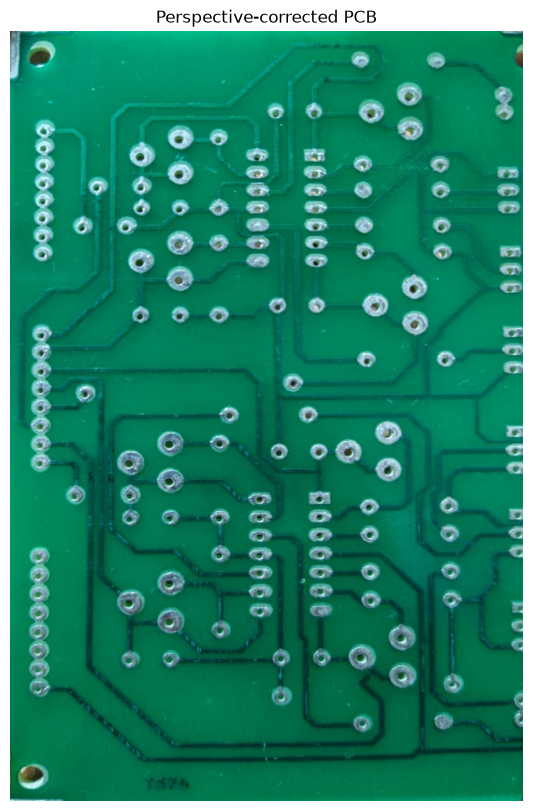

Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_rectified.jpg


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Four PCB corners: top-left, top-right, bottom-right, bottom-left
src_points = np.float32([
    [135, 105],
    [855, 130],
    [805, 1210],
    [165, 1230]
])

# Output dimensions
width = 800
height = 1200

dst_points = np.float32([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
])

# Calculate perspective transformation
matrix = cv2.getPerspectiveTransform(src_points, dst_points)

# Correct perspective
rectified = cv2.warpPerspective(
    image,
    matrix,
    (width, height)
)

# Display result
rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 10))
plt.imshow(rectified_rgb)
plt.title("Perspective-corrected PCB")
plt.axis("off")
plt.show()

# Save without modifying the original image
output_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_rectified.jpg"
)

cv2.imwrite(str(output_path), rectified)
print("Saved:", output_path)

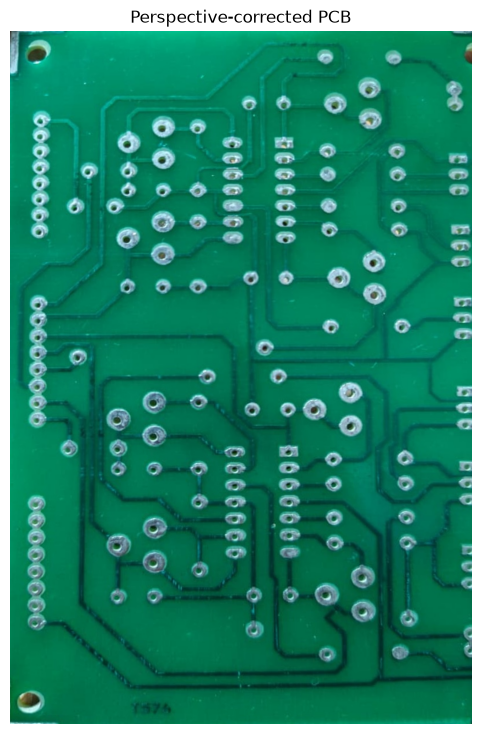

Image dimensions: (1200, 800, 3)


In [6]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

rectified_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_rectified.jpg"
)

rectified = cv2.imread(str(rectified_path))

if rectified is None:
    print("Rectified image not found. Check the previous cell's output.")
else:
    rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 9))
    plt.imshow(rectified_rgb)
    plt.title("Perspective-corrected PCB")
    plt.axis("off")
    plt.show()

    print("Image dimensions:", rectified.shape)

Saved: D:\PCB Defect Detection\results\perspective_correction\green_pcb_rectified.jpg
Image dimensions: (1200, 800, 3)


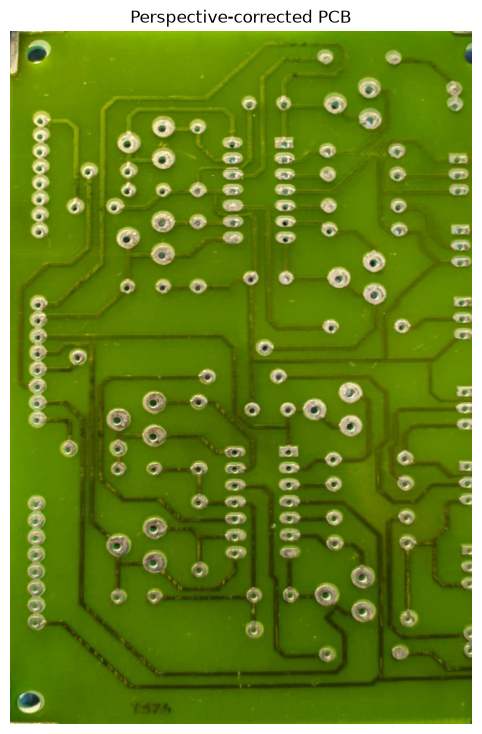

In [7]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

output_dir = Path(r"D:\PCB Defect Detection\results\perspective_correction")
output_dir.mkdir(parents=True, exist_ok=True)

rectified_path = output_dir / "green_pcb_rectified.jpg"

cv2.imwrite(str(rectified_path), cv2.cvtColor(rectified, cv2.COLOR_RGB2BGR))

print("Saved:", rectified_path)
print("Image dimensions:", rectified.shape)

plt.figure(figsize=(7, 9))
plt.imshow(rectified)
plt.title("Perspective-corrected PCB")
plt.axis("off")
plt.show()

Tiles processed: 15
Detections before NMS: 61
Detections after NMS: 25
Class counts: Counter({'missing_hole': 25})
Saved: D:\PCB Defect Detection\results\perspective_correction\green_pcb_rectified_tiled.jpg


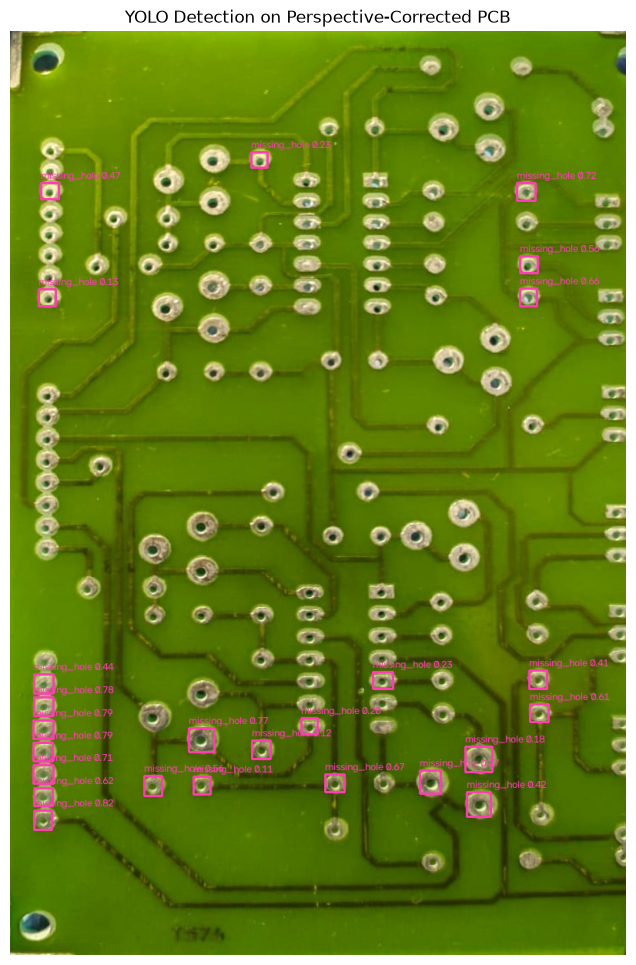

In [8]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load the trained model
model_path = Path(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)
model = YOLO(str(model_path))

# 2. Load the perspective-corrected PCB
image_path = Path(
    r"D:\PCB Defect Detection\results\perspective_correction\green_pcb_rectified.jpg"
)

image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
H, W = image_rgb.shape[:2]

# 3. Tile settings
tile_w = 480
tile_h = 360
overlap = 0.20
stride_x = int(tile_w * (1 - overlap))
stride_y = int(tile_h * (1 - overlap))

all_boxes = []
all_scores = []
all_classes = []

# 4. Run YOLO on every overlapping tile
for y in range(0, H, stride_y):
    for x in range(0, W, stride_x):
        x1 = min(x, max(0, W - tile_w))
        y1 = min(y, max(0, H - tile_h))
        x2 = min(W, x1 + tile_w)
        y2 = min(H, y1 + tile_h)

        tile = image_rgb[y1:y2, x1:x2]

        if tile.size == 0:
            continue

        result = model.predict(
            source=tile,
            imgsz=608,
            conf=0.10,
            device=0,
            verbose=False
        )[0]

        if result.boxes is None or len(result.boxes) == 0:
            continue

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy().astype(int)

        # Map tile coordinates back to the full corrected image
        boxes[:, [0, 2]] += x1
        boxes[:, [1, 3]] += y1

        all_boxes.extend(boxes.tolist())
        all_scores.extend(scores.tolist())
        all_classes.extend(classes.tolist())

# 5. Merge duplicate boxes class-by-class using NMS
final_boxes = []
final_scores = []
final_classes = []

if all_boxes:
    all_boxes = np.asarray(all_boxes, dtype=np.float32)
    all_scores = np.asarray(all_scores, dtype=np.float32)
    all_classes = np.asarray(all_classes, dtype=np.int32)

    for class_id in np.unique(all_classes):
        indices = np.where(all_classes == class_id)[0]

        boxes_xywh = []
        for x1, y1, x2, y2 in all_boxes[indices]:
            boxes_xywh.append([
                x1, y1, x2 - x1, y2 - y1
            ])

        keep = cv2.dnn.NMSBoxes(
            boxes_xywh,
            all_scores[indices].tolist(),
            score_threshold=0.10,
            nms_threshold=0.45
        )

        if len(keep) > 0:
            keep = np.asarray(keep).reshape(-1)
            selected = indices[keep]

            final_boxes.extend(all_boxes[selected].tolist())
            final_scores.extend(all_scores[selected].tolist())
            final_classes.extend(all_classes[selected].tolist())

# 6. Draw the final detections
annotated = image_rgb.copy()

for box, score, class_id in zip(
    final_boxes, final_scores, final_classes
):
    x1, y1, x2, y2 = map(int, box)
    label = f"{model.names[class_id]} {score:.2f}"

    cv2.rectangle(
        annotated, (x1, y1), (x2, y2), (255, 60, 180), 2
    )
    cv2.putText(
        annotated,
        label,
        (x1, max(18, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        (255, 60, 180),
        1,
        cv2.LINE_AA
    )

# 7. Save and display the result
output_path = Path(
    r"D:\PCB Defect Detection\results\perspective_correction"
    r"\green_pcb_rectified_tiled.jpg"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_path),
    cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)
)

from collections import Counter

print("Tiles processed:", len(range(0, H, stride_y)) *
      len(range(0, W, stride_x)))
print("Detections before NMS:", len(all_scores))
print("Detections after NMS:", len(final_scores))
print("Class counts:", Counter(
    model.names[c] for c in final_classes
))
print("Saved:", output_path)

plt.figure(figsize=(10, 12))
plt.imshow(annotated)
plt.title("YOLO Detection on Perspective-Corrected PCB")
plt.axis("off")
plt.show()
